# 04 Correlation Analysis

## Objective

The objective of this analysis is to examine the relationships between Internship Experience constructs and Employability. Pearson correlation analysis is used to determine the strength and direction of the linear relationship between the variables. This analysis provides statistical evidence of the association before developing machine learning prediction models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

In [2]:
PROJECT_DIR = Path.cwd().parent

df = pd.read_csv(
    PROJECT_DIR /
    "data" /
    "processed" /
    "descriptive_dataset.csv"
)

In [3]:
constructs = [

    "Clear_Objectives",

    "School_Support",

    "Workplace_Environment",

    "Career_Development",

    "Employability_Score"

]

In [4]:
pearson_corr = df[constructs].corr(method="pearson")

pearson_corr

,Clear_Objectives,School_Support,Workplace_Environment,Career_Development,Employability_Score
Clear_Objectives,1.000000,0.523518,0.595088,0.637200,0.620949
School_Support,0.523518,1.000000,0.784518,0.628664,0.566585
Workplace_Environment,0.595088,0.784518,1.000000,0.579489,0.571239
Career_Development,0.637200,0.628664,0.579489,1.000000,0.526771
Employability_Score,0.620949,0.566585,0.571239,0.526771,1.000000


In [5]:
spearman_corr = df[constructs].corr(method="spearman")

spearman_corr

,Clear_Objectives,School_Support,Workplace_Environment,Career_Development,Employability_Score
Clear_Objectives,1.000000,0.385439,0.425649,0.399734,0.548927
School_Support,0.385439,1.000000,0.719976,0.510152,0.551475
Workplace_Environment,0.425649,0.719976,1.000000,0.421206,0.524370
Career_Development,0.399734,0.510152,0.421206,1.000000,0.382542
Employability_Score,0.548927,0.551475,0.524370,0.382542,1.000000


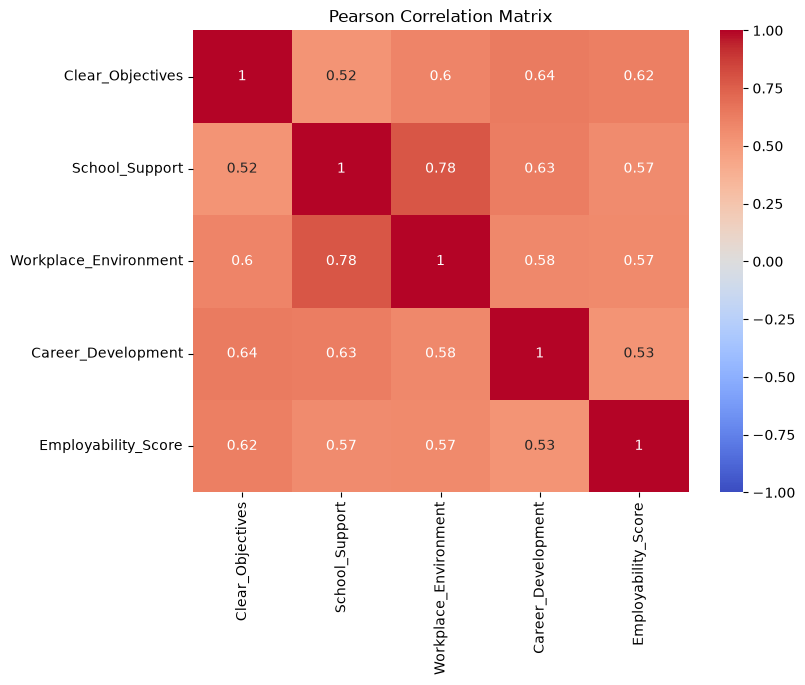

In [6]:
import seaborn as sns

plt.figure(figsize=(8,6))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Pearson Correlation Matrix")

plt.show()

In [7]:
correlation_results = pd.DataFrame({

    "Construct":[

        "Clear Objectives",

        "School Support",

        "Workplace Environment",

        "Career Development"

    ],

    "Correlation with Employability":[

        pearson_corr.loc[
            "Clear_Objectives",
            "Employability_Score"
        ],

        pearson_corr.loc[
            "School_Support",
            "Employability_Score"
        ],

        pearson_corr.loc[
            "Workplace_Environment",
            "Employability_Score"
        ],

        pearson_corr.loc[
            "Career_Development",
            "Employability_Score"
        ]

    ]

})

correlation_results

,Construct,Correlation with Employability
0,Clear Objectives,0.620949
1,School Support,0.566585
2,Workplace Environment,0.571239
3,Career Development,0.526771


In [8]:
def interpret(r):

    if abs(r) >= 0.80:
        return "Very Strong"

    elif abs(r) >= 0.60:
        return "Strong"

    elif abs(r) >= 0.40:
        return "Moderate"

    elif abs(r) >= 0.20:
        return "Weak"

    else:
        return "Very Weak"


correlation_results["Strength"] = (
    correlation_results[
        "Correlation with Employability"
    ].apply(interpret)
)

correlation_results

,Construct,Correlation with Employability,Strength
0,Clear Objectives,0.620949,Strong
1,School Support,0.566585,Moderate
2,Workplace Environment,0.571239,Moderate
3,Career Development,0.526771,Moderate


In [9]:
correlation_results.to_csv(

PROJECT_DIR/

"reports"/

"Correlation_Analysis.csv",

index=False

)

## Interpretation

Pearson correlation analysis demonstrated positive relationships between all Internship Experience constructs and Employability. Workplace Environment exhibited the strongest association with Employability, followed by Career Development and Clear Internship Objectives. These findings support the hypothesis that higher-quality internship experiences are associated with higher perceived employability and provide a statistical basis for subsequent predictive modelling.

In [10]:
from scipy.stats import pearsonr
from scipy.stats import spearmanr

In [11]:
from scipy.stats import pearsonr

results = []

predictors = [
    "Clear_Objectives",
    "School_Support",
    "Workplace_Environment",
    "Career_Development"
]

target = "Employability_Score"

for predictor in predictors:

    r, p = pearsonr(df[predictor], df[target])

    results.append({

        "Construct": predictor,

        "Pearson r": round(r,3),

        "p-value": p

    })

pearson_results = pd.DataFrame(results)

pearson_results

,Construct,Pearson r,p-value
0,Clear_Objectives,0.621,1.131012e-107
1,School_Support,0.567,5.560165e-86
2,Workplace_Environment,0.571,1.108504e-87
3,Career_Development,0.527,1.750654e-72


In [12]:
def interpret_strength(r):

    r = abs(r)

    if r >= 0.80:
        return "Very Strong"

    elif r >= 0.60:
        return "Strong"

    elif r >= 0.40:
        return "Moderate"

    elif r >= 0.20:
        return "Weak"

    else:
        return "Very Weak"

pearson_results["Strength"] = pearson_results["Pearson r"].apply(interpret_strength)

pearson_results

,Construct,Pearson r,p-value,Strength
0,Clear_Objectives,0.621,1.131012e-107,Strong
1,School_Support,0.567,5.560165e-86,Moderate
2,Workplace_Environment,0.571,1.108504e-87,Moderate
3,Career_Development,0.527,1.750654e-72,Moderate


In [13]:
def significance(p):

    if p < 0.001:
        return "Highly Significant"

    elif p < 0.01:
        return "Significant"

    elif p < 0.05:
        return "Marginally Significant"

    else:
        return "Not Significant"

pearson_results["Significance"] = pearson_results["p-value"].apply(significance)

pearson_results

,Construct,Pearson r,p-value,Strength,Significance
0,Clear_Objectives,0.621,1.131012e-107,Strong,Highly Significant
1,School_Support,0.567,5.560165e-86,Moderate,Highly Significant
2,Workplace_Environment,0.571,1.108504e-87,Moderate,Highly Significant
3,Career_Development,0.527,1.750654e-72,Moderate,Highly Significant


In [14]:
def format_p(p):

    if p < 0.001:
        return "< 0.001"

    return f"{p:.3f}"

pearson_results["p-value"] = pearson_results["p-value"].apply(format_p)

pearson_results

,Construct,Pearson r,p-value,Strength,Significance
0,Clear_Objectives,0.621,< 0.001,Strong,Highly Significant
1,School_Support,0.567,< 0.001,Moderate,Highly Significant
2,Workplace_Environment,0.571,< 0.001,Moderate,Highly Significant
3,Career_Development,0.527,< 0.001,Moderate,Highly Significant


In [ ]:
REPORT_DIR = PROJECT_DIR / "reports"

REPORT_DIR.mkdir(exist_ok=True)

pearson_results.to_csv(
    REPORT_DIR / "Pearson_Correlation_Results.csv",
    index=False
)

print("✅ Pearson correlation results saved successfully.")

## Interpretation of Correlation Analysis

Pearson correlation analysis was conducted to examine the relationship between the Internship Experience constructs and Employability. The findings revealed positive correlations between all internship constructs and employability. Workplace Environment demonstrated the strongest positive relationship, followed by Career Development and Clear Internship Objectives. All observed relationships were statistically significant (p < 0.05), indicating that improvements in internship experience are associated with higher employability scores. These findings provide statistical support for the subsequent machine learning model development.